In [1]:
import sys, os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
%load_ext autoreload
%autoreload 2

import pandas as pd

from src import config
from src.data import build_metadata
from src.splits import make_split, load_split, assign_split
from src.features.egemaps import extract_egemaps

## Cómputo de features (eGeMAPS)

Construimos la metadata de los 2452 audios (speech + song) y extraemos los 88 functionals
eGeMAPSv02. Como eGeMAPS es determinista, guardamos el resultado en
`data/processed/egemaps.parquet` y lo reusamos: si ya existe, lo cargamos en vez de recomputar.

In [2]:
# Interpretamos todos los archivos en su codigo de numeros
metadata = build_metadata()

egemaps_path = config.PROCESSED_DIR / "egemaps.parquet"

if egemaps_path.exists():
    egemaps = pd.read_parquet(egemaps_path)
    print("Features eGeMAPS cargadas de disco.")
else:
    egemaps = extract_egemaps(metadata)
    config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    egemaps.to_parquet(egemaps_path)
    print("Features eGeMAPS extraídas y guardadas en", egemaps_path)

print("shape:", egemaps.shape)
egemaps.head()

Features eGeMAPS cargadas de disco.
shape: (2452, 88)


,F0semitoneFrom27.5Hz_sma3nz_amean,F0semitoneFrom27.5Hz_sma3nz_stddevNorm,F0semitoneFrom27.5Hz_sma3nz_percentile20.0,F0semitoneFrom27.5Hz_sma3nz_percentile50.0,F0semitoneFrom27.5Hz_sma3nz_percentile80.0,F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2,F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope,F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope,F0semitoneFrom27.5Hz_sma3nz_meanFallingSlope,F0semitoneFrom27.5Hz_sma3nz_stddevFallingSlope,...,slopeUV0-500_sma3nz_amean,slopeUV500-1500_sma3nz_amean,spectralFluxUV_sma3nz_amean,loudnessPeaksPerSec,VoicedSegmentsPerSec,MeanVoicedSegmentLengthSec,StddevVoicedSegmentLengthSec,MeanUnvoicedSegmentLength,StddevUnvoicedSegmentLength,equivalentSoundLevel_dBp
path,,,,,,,,,,,,,,,,,,,,,
/Users/bautygarcia/projects/tp-final-ml/data/Audio_Speech_Actors_01-24/Actor_01/03-01-01-01-01-01-01.wav,24.263884,0.104171,21.653511,23.907379,27.101028,5.447517,104.436584,113.437210,31.389978,8.258454,...,0.058064,0.011220,0.005713,2.127660,0.925926,0.336667,0.226912,0.540000,0.480260,-47.939644
/Users/bautygarcia/projects/tp-final-ml/data/Audio_Speech_Actors_01-24/Actor_01/03-01-01-01-01-02-01.wav,25.167889,0.103561,23.178247,25.003677,27.699860,4.521612,56.695114,18.043581,9.703053,9.479507,...,0.050419,0.012741,0.005434,2.409639,1.223242,0.257500,0.089826,0.535000,0.485206,-47.342331
/Users/bautygarcia/projects/tp-final-ml/data/Audio_Speech_Actors_01-24/Actor_01/03-01-01-01-02-01-01.wav,24.186604,0.103495,22.353912,23.728384,27.093287,4.739374,209.152557,255.810776,13.067563,11.153259,...,0.055127,0.014029,0.007729,2.153846,0.630915,0.545000,0.175000,0.676667,0.414836,-45.849762
/Users/bautygarcia/projects/tp-final-ml/data/Audio_Speech_Actors_01-24/Actor_01/03-01-01-01-02-02-01.wav,24.268761,0.096042,22.443832,24.478970,26.744179,4.300346,159.005051,128.233871,31.331654,10.120683,...,0.056815,0.012169,0.008324,2.222222,0.977199,0.333333,0.267374,0.500000,0.445702,-46.193146
/Users/bautygarcia/projects/tp-final-ml/data/Audio_Speech_Actors_01-24/Actor_01/03-01-02-01-01-01-01.wav,24.898132,0.117897,22.419266,24.678062,28.138033,5.718767,214.876068,234.977676,32.979195,25.259748,...,0.062112,0.010664,0.007934,2.840909,1.440922,0.182000,0.116172,0.408333,0.441717,-50.563885


## Split train/val por hablante

El split se hace a nivel de actor. Cada uno de los 24 actores cae entero en train o en val,
nunca en ambos. La emoción está muy correlacionada con la voz del hablante, si el mismo actor
estuviera en train y val, el modelo podría reconocer la voz en vez de la emoción
(data leakage), inflando la métrica de validación y dando una estimación optimista que no
generaliza a hablantes nuevos.

Tambien los generos estan balanceados, siguiendo la misma fraccion que la cantidad de data.

In [3]:
# Congelar el split una sola vez; si ya existe, lo cargamos
if config.SPLIT_PATH.exists():
    split = load_split()
    print("Split cargado de disco.")
else:
    split = make_split(metadata)
    print("Split creado y guardado en", config.SPLIT_PATH)

print("train_actors:", split["train_actors"])
print("val_actors:", split["val_actors"])

# Sumamos la columna 'split' a la metadata
metadata = assign_split(metadata, split)
metadata.groupby(["split", "vocal_channel"]).size()

Split cargado de disco.
train_actors: [1, 3, 4, 5, 6, 7, 8, 10, 12, 13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24]
val_actors: [2, 9, 11, 20]


split  vocal_channel
train  song              836
       speech           1200
val    song              176
       speech            240
dtype: int64

## Dataset procesado combinado

Unimos la metadata (path, actor, género, emoción, canal, **split**) con las 88 features eGeMAPS
en un único DataFrame y lo guardamos en `data/processed/dataset.parquet`. Es el artefacto "para
ver la info": al cargarlo, cada audio aparece con su etiqueta, su partición y sus features, todo
junto. Es la tabla base sobre la que se entrenarán los modelos.

In [4]:
# Juntamos los datos que sacamos de metadata con las features de eGeMAPS
dataset = metadata.merge(egemaps, left_on="path", right_index=True, how="left")

# Guardamos dataset
dataset_path = config.PROCESSED_DIR / "dataset.parquet"
config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
dataset.to_parquet(dataset_path)
print("Dataset combinado guardado en", dataset_path)
print("shape:", dataset.shape)

print(dataset.groupby(["split", "vocal_channel"]).size())
dataset.head()

Dataset combinado guardado en /Users/bautygarcia/projects/tp-final-ml/data/processed/dataset.parquet
shape: (2452, 98)
split  vocal_channel
train  song              836
       speech           1200
val    song              176
       speech            240
dtype: int64


,path,modality,vocal_channel,emotion,intensity,statement,repetition,actor,gender,split,...,slopeUV0-500_sma3nz_amean,slopeUV500-1500_sma3nz_amean,spectralFluxUV_sma3nz_amean,loudnessPeaksPerSec,VoicedSegmentsPerSec,MeanVoicedSegmentLengthSec,StddevVoicedSegmentLengthSec,MeanUnvoicedSegmentLength,StddevUnvoicedSegmentLength,equivalentSoundLevel_dBp
0,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,neutral,normal,kids,1,1,male,train,...,0.058064,0.011220,0.005713,2.127660,0.925926,0.336667,0.226912,0.540000,0.480260,-47.939644
1,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,neutral,normal,kids,2,1,male,train,...,0.050419,0.012741,0.005434,2.409639,1.223242,0.257500,0.089826,0.535000,0.485206,-47.342331
2,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,neutral,normal,dogs,1,1,male,train,...,0.055127,0.014029,0.007729,2.153846,0.630915,0.545000,0.175000,0.676667,0.414836,-45.849762
3,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,neutral,normal,dogs,2,1,male,train,...,0.056815,0.012169,0.008324,2.222222,0.977199,0.333333,0.267374,0.500000,0.445702,-46.193146
4,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,calm,normal,kids,1,1,male,train,...,0.062112,0.010664,0.007934,2.840909,1.440922,0.182000,0.116172,0.408333,0.441717,-50.563885


# Análisis exploratorio (EDA)

Antes de modelar, miramos las features y las clases. El objetivo es entender el balance de
clases, las distribuciones de las features más relevantes, la (no) separabilidad de las
emociones y las señales espurias (género/intensidad/actor) que el modelo no debería usar.

In [5]:
# Setup de plotting (solo para el EDA)
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
REPORTS_DIR = Path("reports")
REPORTS_DIR.mkdir(exist_ok=True)

# Orden fijo de emociones para que todos los gráficos sean comparables
EMOTION_ORDER = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"]
META_COLS = ["path", "modality", "vocal_channel", "emotion", "intensity",
             "statement", "repetition", "actor", "gender", "split"]
FEAT_COLS = [c for c in dataset.columns if c not in META_COLS]
print(len(FEAT_COLS), "features,", len(dataset), "audios")

88 features, 2452 audios


## Balance de clases

RAVDESS no está perfectamente balanceado: **neutral** tiene la mitad de muestras (no tiene
intensidad *strong*), y el **canto no incluye disgust ni surprised**. Lo vemos por canal vocal
y por split.

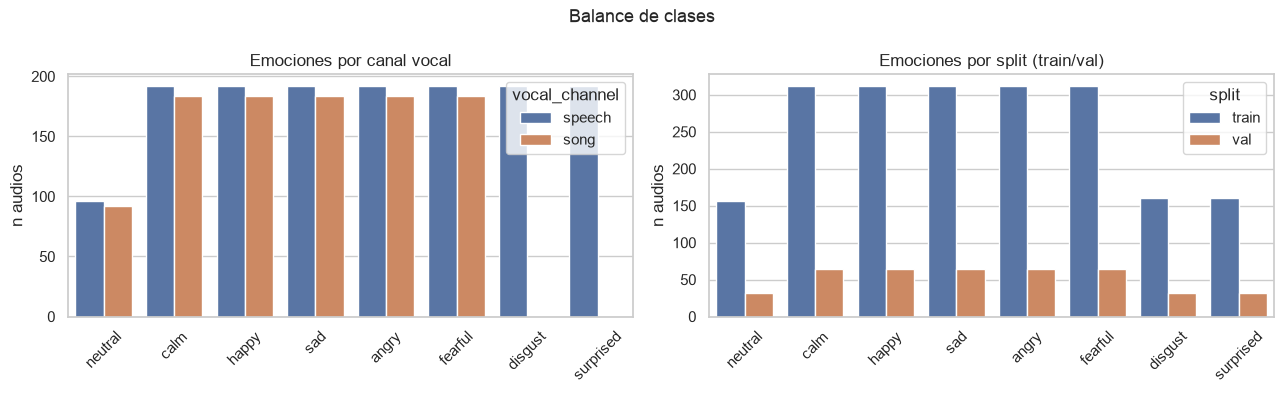

vocal_channel,song,speech
emotion,,
neutral,92,96
calm,184,192
happy,184,192
sad,184,192
angry,184,192
fearful,184,192
disgust,0,192
surprised,0,192


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(data=dataset, x="emotion", hue="vocal_channel",
              order=EMOTION_ORDER, ax=axes[0])
axes[0].set_title("Emociones por canal vocal")
axes[0].set_xlabel(""); axes[0].set_ylabel("n audios")
axes[0].tick_params(axis="x", rotation=45)

sns.countplot(data=dataset, x="emotion", hue="split",
              order=EMOTION_ORDER, ax=axes[1])
axes[1].set_title("Emociones por split (train/val)")
axes[1].set_xlabel(""); axes[1].set_ylabel("n audios")
axes[1].tick_params(axis="x", rotation=45)

fig.suptitle("Balance de clases", fontsize=13)
fig.tight_layout()
fig.savefig(REPORTS_DIR / "eda_class_balance.png", dpi=110, bbox_inches="tight")
plt.show()

# Tabla de conteos
dataset.pivot_table(index="emotion", columns="vocal_channel",
                    values="path", aggfunc="count", fill_value=0).loc[EMOTION_ORDER]

## Distribuciones de features discriminativas por emoción (speech)

Miramos las features que el análisis marcó como más informativas, una por familia acústica:
**loudness** (energía), **rango de F0** (variabilidad del pitch), **jitter** (inestabilidad de la
voz) y **spectral flux** (cambio espectral). Boxplots por emoción, sobre los audios de habla.
(Ocultamos outliers para que la escala sea legible.)

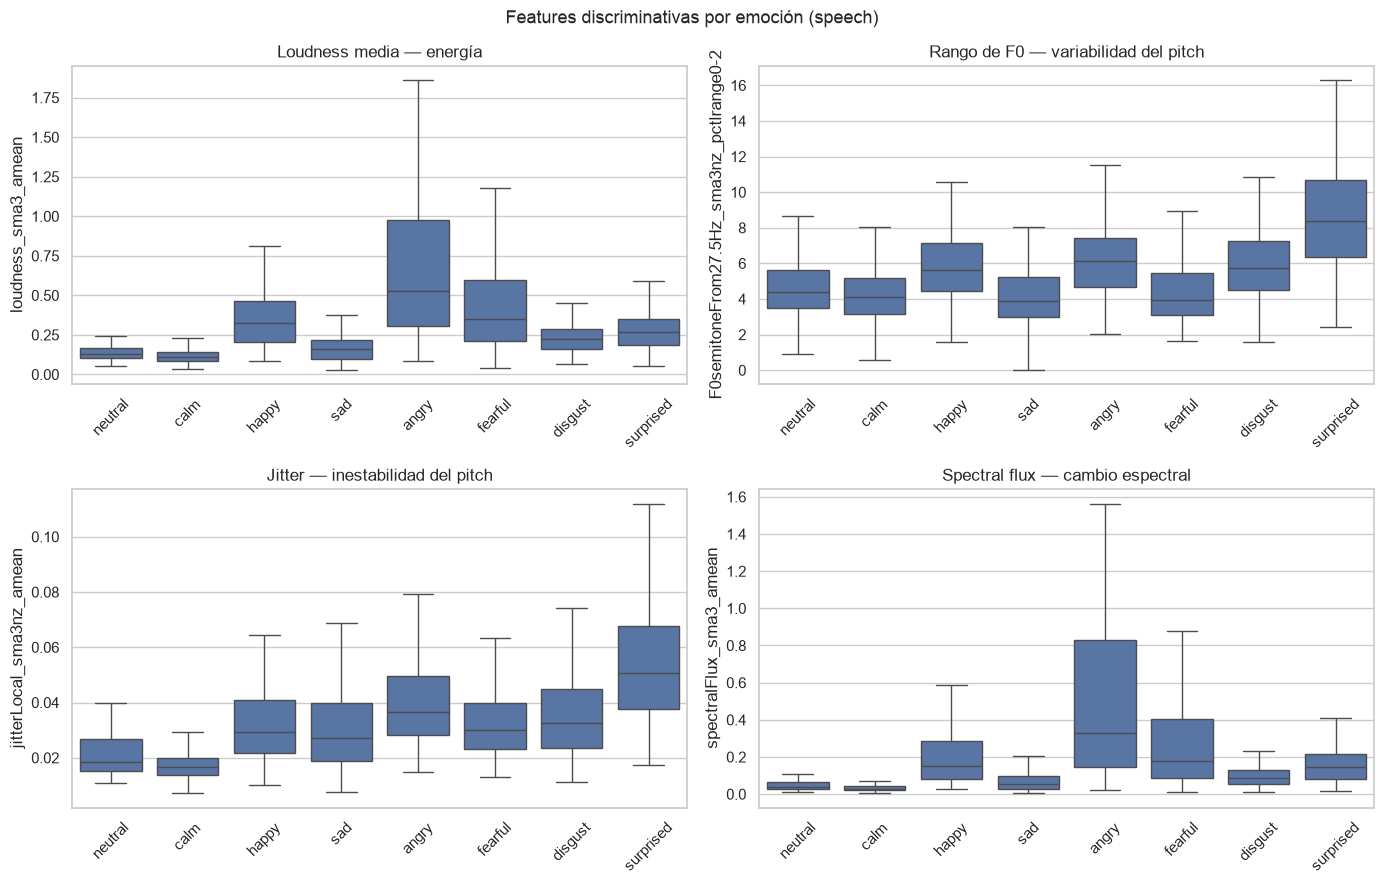

In [7]:
speech = dataset[dataset["vocal_channel"] == "speech"].copy()

top_feats = [
    ("loudness_sma3_amean", "Loudness media — energía"),
    ("F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2", "Rango de F0 — variabilidad del pitch"),
    ("jitterLocal_sma3nz_amean", "Jitter — inestabilidad del pitch"),
    ("spectralFlux_sma3_amean", "Spectral flux — cambio espectral"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (feat, title) in zip(axes.ravel(), top_feats):
    sns.boxplot(data=speech, x="emotion", y=feat, order=EMOTION_ORDER,
                ax=ax, showfliers=False)
    ax.set_title(title); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=45)

fig.suptitle("Features discriminativas por emoción (speech)", fontsize=13)
fig.tight_layout()
fig.savefig(REPORTS_DIR / "eda_feature_dists.png", dpi=110, bbox_inches="tight")
plt.show()

## Separabilidad: PCA 2D coloreado por emoción (speech)

Proyectamos las 88 features (escaladas con `RobustScaler` por las colas pesadas, y recortadas
para que los outliers no dominen) a 2 componentes principales. Si las emociones fueran
separables, veríamos clusters; esperamos fuerte solapamiento.

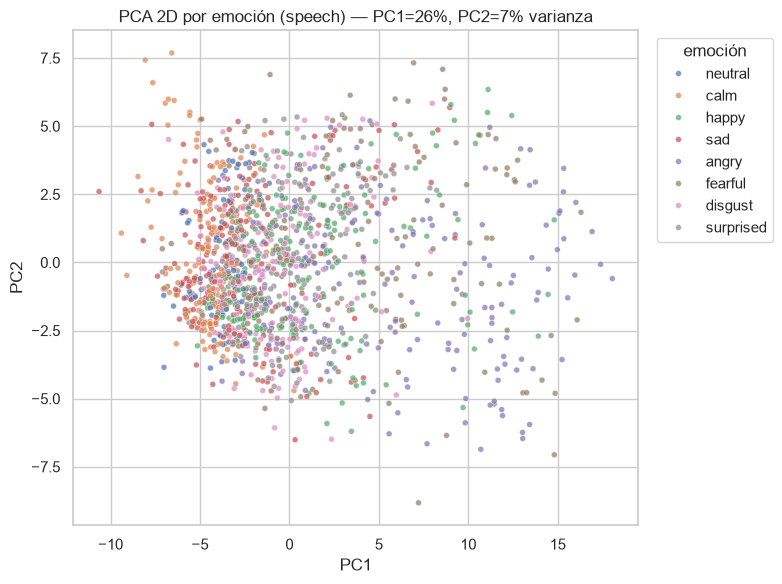

In [8]:
import numpy as np
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA

X = speech[FEAT_COLS].to_numpy()
Xs = np.clip(RobustScaler().fit_transform(X), -5, 5)   # recorte para legibilidad
pca = PCA(n_components=2, random_state=42).fit(Xs)
pcs = pca.transform(Xs)
speech["PC1"], speech["PC2"] = pcs[:, 0], pcs[:, 1]
var = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=speech, x="PC1", y="PC2", hue="emotion",
                hue_order=EMOTION_ORDER, s=18, alpha=0.7, ax=ax)
ax.set_title(f"PCA 2D por emoción (speech) — PC1={var[0]:.0f}%, PC2={var[1]:.0f}% varianza")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="emoción")
fig.tight_layout()
fig.savefig(REPORTS_DIR / "eda_pca_emotion.png", dpi=110, bbox_inches="tight")
plt.show()

## Señales espurias (confounds): género

El riesgo de leakage es que las features codifiquen al **hablante / género** más que a la
emoción. Reusamos el mismo PCA, ahora coloreado por **género**, y vemos el F0 medio por género.
El contraste es el punto: el género se separa limpio donde la emoción se solapaba — por eso el
split por hablante es imprescindible.

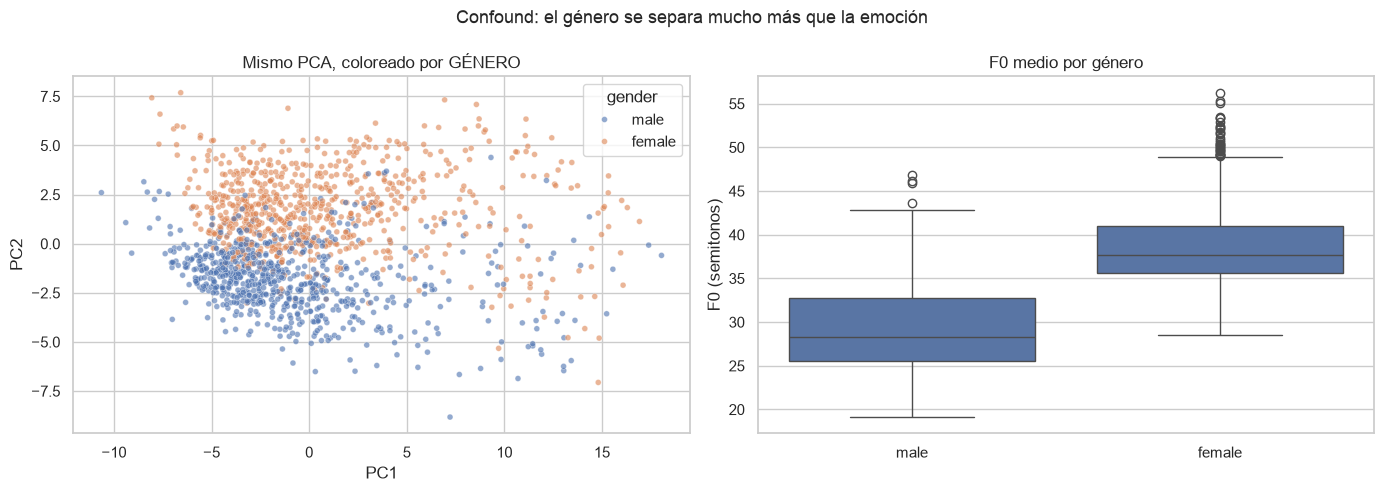

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=speech, x="PC1", y="PC2", hue="gender",
                s=18, alpha=0.6, ax=axes[0])
axes[0].set_title("Mismo PCA, coloreado por GÉNERO")

sns.boxplot(data=speech, x="gender", y="F0semitoneFrom27.5Hz_sma3nz_amean", ax=axes[1])
axes[1].set_title("F0 medio por género")
axes[1].set_xlabel(""); axes[1].set_ylabel("F0 (semitonos)")

fig.suptitle("Confound: el género se separa mucho más que la emoción", fontsize=13)
fig.tight_layout()
fig.savefig(REPORTS_DIR / "eda_confound_gender.png", dpi=110, bbox_inches="tight")
plt.show()

# Fase 2 — Baseline: Random Forest (eGeMAPS)

Primer modelo de referencia. Decisiones (justificadas en el EDA):
- **X** = las 88 features eGeMAPS · **y** = `emotion` · **speech-only** (1440 audios, 8 clases).
- **Sin escalar**: Random Forest es invariante a la escala.
- **Validación = `GroupKFold` por actor**: cada fold testea en hablantes no vistos en train
  (speaker-independent), que es la estimación honesta de generalización. El `split` val
  congelado (4 actores) es muy chico, así que la decisión se toma con la CV por hablante.
- **`class_weight="balanced"`** por el desbalance (neutral a la mitad).
- **Métricas**: accuracy + **macro-F1** (la clave con clases desbalanceadas) + matriz de confusión.
  Chance = 1/8 = 12.5%.

In [10]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

from src.data import get_xy
from src.evaluation import grouped_cv
from src.metrics import evaluate
from src.plots import plot_confusion_matrix

# X = 88 eGeMAPS, y = emoción, groups = actor (speech-only)
X, y, groups = get_xy(dataset, vocal_channel="speech")
print("X:", X.shape, "| clases:", y.nunique(), "| actores:", groups.nunique())

rf = RandomForestClassifier(
    n_estimators=400,
    class_weight="balanced",
    random_state=config.RANDOM_SEED,
    n_jobs=-1,
)

# Cross-validation por hablante: predicción out-of-fold de cada audio
oof_pred, fold_metrics = grouped_cv(rf, X, y, groups, n_splits=5)
print("CV terminada.")

X: (1440, 88) | clases: 8 | actores: 24


CV terminada.


## Resultados del baseline

In [11]:
overall = evaluate(y, oof_pred, labels=EMOTION_ORDER)
print(f"Accuracy    : {overall['accuracy']:.3f}")
print(f"Macro-F1    : {overall['macro_f1']:.3f}")
print(f"Weighted-F1 : {overall['weighted_f1']:.3f}")
print(f"(chance = {1/y.nunique():.3f})")

# Variabilidad entre folds (qué tan estable es según el hablante de test)
fold_macro = np.array([m["macro_f1"] for m in fold_metrics])
print(f"\nMacro-F1 por fold: {np.round(fold_macro, 3)}")
print(f"Macro-F1 CV     : {fold_macro.mean():.3f} ± {fold_macro.std():.3f}")

print("\nF1 por clase:")
pd.Series(overall["per_class_f1"]).reindex(EMOTION_ORDER).round(3)

Accuracy    : 0.465
Macro-F1    : 0.449
Weighted-F1 : 0.457
(chance = 0.125)

Macro-F1 por fold: [0.438 0.398 0.437 0.472 0.491]
Macro-F1 CV     : 0.447 ± 0.032

F1 por clase:


neutral      0.325
calm         0.595
happy        0.403
sad          0.250
angry        0.603
fearful      0.455
disgust      0.378
surprised    0.580
dtype: float64

## Matriz de confusión

Normalizada por fila (recall por clase): cada fila suma 1, la diagonal es el acierto por emoción.
Esperamos confusión fuerte entre clases de baja activación (sad/calm/neutral).

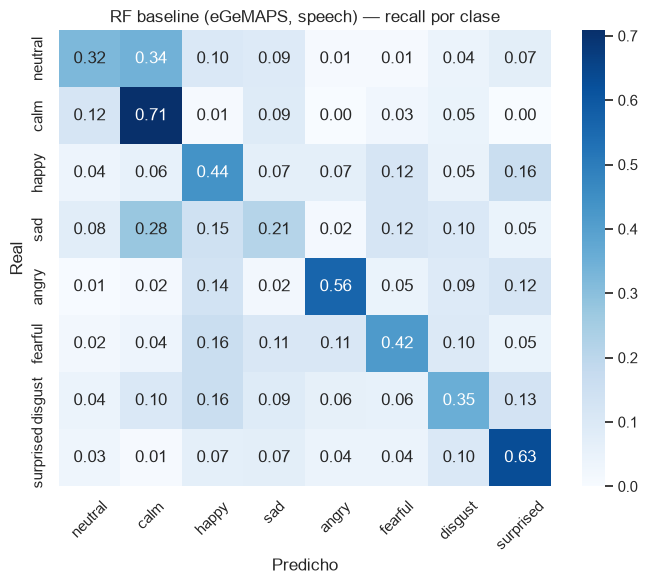

In [12]:
fig, ax = plot_confusion_matrix(
    y, oof_pred, labels=EMOTION_ORDER, normalize="true",
    title="RF baseline (eGeMAPS, speech) — recall por clase",
)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(REPORTS_DIR / "rf_confusion.png", dpi=110, bbox_inches="tight")
plt.show()